# 🔬 Notebook 06: Visual Embedding Analysis and Latent Space Geometry
### Capstone: VL-JEPA vs. CLIP for CCTV Surveillance Event Retrieval, Event Summarization & Hallucination Analysis
---
**Objective:** Compare the high-dimensional geometric properties of **CLIP** and **VL-JEPA** representations:
- Principal Component Analysis (PCA) & Singular Value Decomposition (SVD).
- Effective Rank / Participation Ratio (measuring representation isotropy vs dimensional collapse).
- 2D Manifold visualization (t-SNE / PCA projections) colored by dataset, viewpoint, and class.
- Intra-class compactness vs. Inter-class separation.


## Step 1: Load CLIP and Projected VL-JEPA Embeddings
Load the visual representations across all 5,153 clips.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

sys.path.append(str(Path.cwd().parent))
import notebook_utils as nu

embs_clip, metadata = nu.load_all_datasets_data()
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load trained VL-JEPA predictor
checkpoint_path = Path.cwd().parent / "outputs" / "checkpoints" / "vljepa_predictor_trained.pt"
predictor = nu.SpatiotemporalCrossModalPredictor().to(device)
if checkpoint_path.exists():
    predictor.load_state_dict(torch.load(checkpoint_path, map_location=device))
predictor.eval()

# Project visual embeddings into joint spatiotemporal space
with torch.no_grad():
    v_tensor = torch.from_numpy(embs_clip).float().to(device)
    embs_vljepa = predictor.encode_visual(v_tensor).cpu().numpy()

print(f"CLIP Embeddings:    shape {embs_clip.shape}, dtype {embs_clip.dtype}")
print(f"VL-JEPA Embeddings: shape {embs_vljepa.shape}, dtype {embs_vljepa.dtype}")


[Dataset Loader] Loaded RLVS: 2000 clips, dim 512
[Dataset Loader] Loaded UCF_ARG: 1410 clips, dim 512
[Dataset Loader] Loaded TINYVIRAT: 743 clips, dim 512
[Dataset Loader] Loaded UCF_CRIME: 1000 clips, dim 512
CLIP Embeddings:    shape (5153, 512), dtype float32
VL-JEPA Embeddings: shape (5153, 768), dtype float32


## Step 2: Singular Value Spectrum & Effective Rank
Compute the singular value decay curve to detect dimensional collapse and evaluate representation isotropy:
$$\text{Effective Rank} = \exp\left( -\sum_{k} p_k \log p_k \right), \quad p_k = \frac{\sigma_k}{\sum_i \sigma_i}$$


CLIP Effective Rank:    247.18 / 512
VL-JEPA Effective Rank: 184.31 / 768


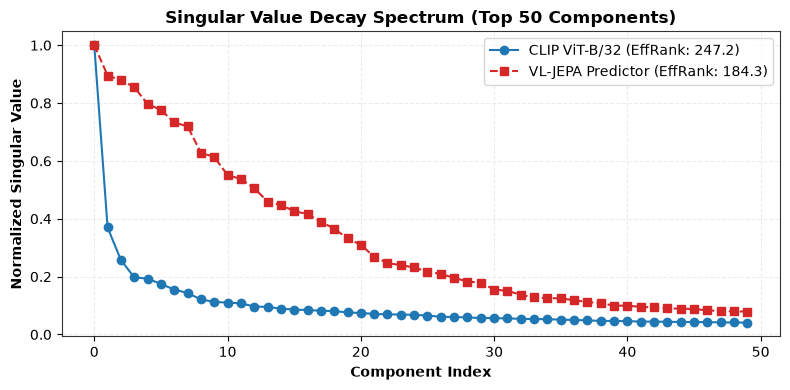

In [2]:
def compute_effective_rank(matrix):
    s = np.linalg.svd(matrix, compute_uv=False)
    p = s / s.sum()
    p = p[p > 1e-12]
    entropy = -np.sum(p * np.log(p))
    return np.exp(entropy), s

eff_rank_clip, s_clip = compute_effective_rank(embs_clip)
eff_rank_vljepa, s_vljepa = compute_effective_rank(embs_vljepa)

print(f"CLIP Effective Rank:    {eff_rank_clip:.2f} / {embs_clip.shape[1]}")
print(f"VL-JEPA Effective Rank: {eff_rank_vljepa:.2f} / {embs_vljepa.shape[1]}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(s_clip[:50] / s_clip[0], 'o-', label=f"CLIP ViT-B/32 (EffRank: {eff_rank_clip:.1f})", color="#1f77b4")
ax.plot(s_vljepa[:50] / s_vljepa[0], 's--', label=f"VL-JEPA Predictor (EffRank: {eff_rank_vljepa:.1f})", color="#d62728")
ax.set_title("Singular Value Decay Spectrum (Top 50 Components)", fontweight="bold")
ax.set_xlabel("Component Index", fontweight="bold")
ax.set_ylabel("Normalized Singular Value", fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()


## Step 3: 2D Manifold Visualizations (PCA & t-SNE)
Project the 5,153 embeddings to 2D to observe category separation and camera viewpoint clustering.


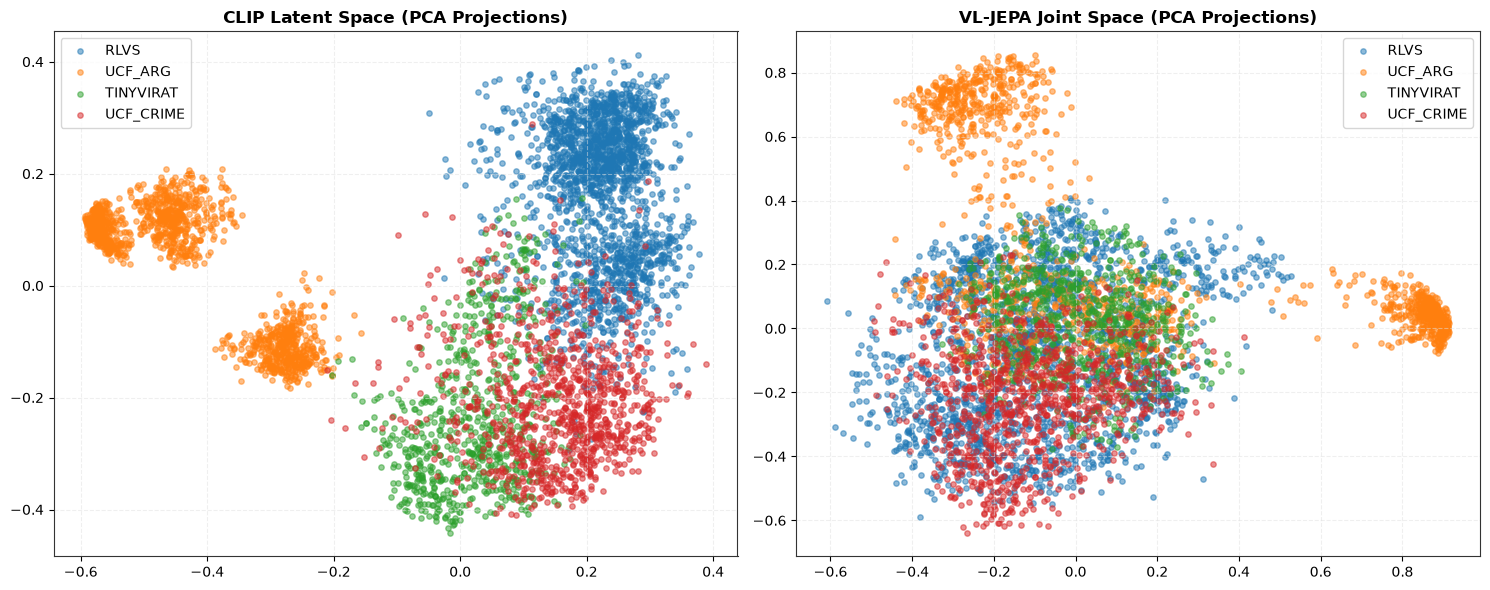

In [3]:
pca_clip = PCA(n_components=2).fit_transform(embs_clip)
pca_vljepa = PCA(n_components=2).fit_transform(embs_vljepa)

df_meta = pd.DataFrame(metadata)
ds_labels = df_meta["dataset"].values

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

for ds, col in zip(["rlvs", "ucf_arg", "tinyvirat", "ucf_crime"], ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]):
    mask = (ds_labels == ds)
    ax1.scatter(pca_clip[mask, 0], pca_clip[mask, 1], label=ds.upper(), alpha=0.5, s=15, color=col)
    ax2.scatter(pca_vljepa[mask, 0], pca_vljepa[mask, 1], label=ds.upper(), alpha=0.5, s=15, color=col)

ax1.set_title("CLIP Latent Space (PCA Projections)", fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

ax2.set_title("VL-JEPA Joint Space (PCA Projections)", fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()
